## Computing Project- Three Body Problem

## Milestone Project

#### Imports and Constants

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as scpo
import scipy.stats
import math
import pandas as pd


class UDS:
    def __init__(self,data_matrix):
        self.data = data_matrix

    @classmethod
    #The bellow function will save the data as a UDS object. The data will be in the form [[row1col1, row1col2,row1col3,...],[row2col1, row2col2, row2col3,...],...]
    def data_excel(cls, file, rows, colums, sheet_nm = "Sheet1"): #"file name",[1,3],"A:B"
        pd_file = pd.read_excel(file + ".xlsx",sheet_name=sheet_nm, usecols= colums)
        just_data = pd_file.iloc[rows[0]-2:rows[1]-1]
        fin_data = just_data.values.tolist()
        return cls(fin_data)
    
    #Utility functions
    @staticmethod
    def flatten(matrix):
        flat_list = []
        for row in matrix:
            flat_list.extend(row)
        return flat_list
    @staticmethod
    def sci_e_equal(num1,num2,round = 10):
        e_1 = 10**(int(math.log10(num1))-1)
        if e_1 < 0.0001:
            e_1_s = "{0}".format(e_1)
            e_1_s = e_1_s[1:]
            prop_num2 = "{0}".format((num2 * e_1**-1))
            return prop_num2 + e_1_s
        else:
            e_2 = -1*(int(math.log10(num2))-round) 
            e_2_f = ':.{0}'.format(e_2)
            e_2_f = '{' + e_2_f + 'f}'
            return e_2_f.format(num2)

    def getData(self):  #Return data matrix
        return self.data

#Bellow are methods to calculate and display the error of a value using the functional aproach

    def functional_err(self, f, return_comp = False):
        comp_err = []
        orig_val = []
        for i in self.data:
            orig_val += [i[0]]
        fin_val = f(*orig_val)

        for i in range(len(self.data)):
            cur_val = orig_val.copy()
            cur_val[i] += self.data[i][1]
            comp_err += [abs(f(*cur_val) - fin_val)]

        fin_err = 0
        for i in comp_err:
            fin_err += i**2
        fin_err = (fin_err)**0.5
        
        if return_comp:
            return [[fin_val, fin_err], comp_err]
        return [fin_val, fin_err]
    
    def display_func_err(self, f, show_comp = False, **kwargs):
        fig = plt.figure(1) 
        fig.add_axes((0,0,0.75,0.10))
        ax = fig.gca()

        fx_name = "Z"
        fx_units = "n/a"
        comp_tbl_row = []  #The labels for the component table rows
        alphabet = ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O","P","Q","R","S","T","U","V","W","X","Y","Z"]

        if 'f_name' in kwargs:
            fx_name = kwargs['f_name']
        if 'f_units' in kwargs:
            fx_units = kwargs['f_units']

        if show_comp:
            all_data = self.functional_err(f,return_comp= True)
            val_fin = all_data[0][0]
            err_fin = all_data[0][1]
            comp_err = all_data[1].copy()
            tbl_comp_err = []  #Holds the actual values to display in the component err table
            var_names = alphabet[:len(self.data)]
            if 'var_names' in kwargs:
                var_names = kwargs['var_names']
            for i in range(len(comp_err)):
                tbl_comp_err += [[comp_err[i]]]
                comp_tbl_row += ["$\\alpha_{0}^{{{1}}}$".format(fx_name,var_names[i])]

        else:
            all_data = self.functional_err(f,return_comp= False)
            val_fin = all_data[0]
            err_fin = all_data[1]


        # hide axes
        ax.axis('off')
        ax.axis('tight')
        axtl = r"{0}\ and\ its\ Error".format(fx_name)
        axtl = "$\\mathbfit{" + axtl + "}$"
        ax.set_title(axtl)
        fx_tbl_contents = [[val_fin,UDS.sci_e_equal(val_fin,err_fin)]]
        fx_tbl_headers = ["${0}$ (${1}$)".format(fx_name,fx_units), "$\\alpha_{0}$ (${1}$)".format(fx_name,fx_units)]

        fx_tbl = ax.table(cellText=fx_tbl_contents,cellLoc="center",colWidths= [0.5,0.5],colLabels=fx_tbl_headers, loc='center') #Table creation
        #setting the height of each cell
        for c in fx_tbl.get_celld().values():
            c.set_height(0.5)


        #### Code for error component tabel
        if show_comp:
            comp_tbl_headers = ["Component of total error (${0}$)".format(fx_units)]
            axis_height = 0.0578*len(comp_err) + 0.1424 #formula to calculate where to begin and the height of the axis based on the amount of component error

            fig.add_axes((0,-1*axis_height,0.75,axis_height))
            ax = fig.gca()
            ax.axis('off')
            ax.axis('tight')


            comp_tbl = ax.table(cellText=tbl_comp_err,cellLoc="center",colWidths=[0.5],colLabels=comp_tbl_headers,rowLabels=comp_tbl_row, loc='center')

            cell_height = 1/(2+len(comp_err))

            for c in comp_tbl.get_celld().values():
                c.set_height(cell_height)
        plt.show()

m_E = 5.9742 * 10**24  # Mass of the Earth in kg
m_M = 7.35 * 10**22 # Mass of the Moon in kg
G = 6.6726 * 10**(-11) # Gravitational constant in N m^2 kg^-2
d = 3.844 * 10**8 #Earth-Moon distance in m
pi = math.pi 

#### Functions and basic values

In [39]:
d_E = d*m_M/(m_M + m_E) # Distance of Earth to center of mass
d_M = d*m_E/(m_M + m_E) # Distance of Moon to center of mass

def kpIII_T(a,M):  #Returns the period of orbit in seconds calculated using Kepler's third law. 'a' is the radius of orbit, and 'M' is mass of system
    G = 6.6726 * 10**(-11)
    return math.sqrt(4*math.pi**2 * a**3/(G*M))

T_EM = kpIII_T(d,m_E+m_M) # Period of Earth-Moon Orbit

def earth_pos_evolver(dt, t_0 = 0):
    theta_0 = (t_0*2*pi/T_EM) + math.pi 
    d_theta = dt*2*pi/T_EM
    tot_theta = theta_0+d_theta
    fin_theta = ((tot_theta/(2*pi))-((tot_theta/(2*pi))//1))*2*pi
    #The above line limits the final angle to be between 0 and 2pi (as in 5pi becomes pi) to mitigate the error caused by the math.trig functios
    return np.array([d_E*math.cos(fin_theta),d_E*math.sin(fin_theta)])  #There is an error produced by the math.sin function and the value of pi

def moon_pos_evolver(dt, t_0 = 0):
    theta_0 = (t_0*2*pi/T_EM)
    d_theta = dt*2*pi/T_EM
    tot_theta = theta_0+d_theta
    fin_theta = ((tot_theta/(2*pi))-((tot_theta/(2*pi))//1))*2*pi #See earth evolver for explanation on errors and angle rounding
    return np.array([d_M*math.cos(fin_theta),d_M*math.sin(fin_theta)])  #There is an error produced by the math.sin function and the value of pi

def EM_pos_evolver(dt,t_0 = 0):
    tot_thetaM = (t_0*2*pi/T_EM)+(dt*2*pi/T_EM)
    tot_thetaE = tot_thetaM + math.pi
    fin_thetaM = ((tot_thetaM/(2*pi))-((tot_thetaM/(2*pi))//1))*2*pi
    fin_thetaE = ((tot_thetaE/(2*pi))-((tot_thetaE/(2*pi))//1))*2*pi
    #The above line limits the final angle to be between 0 and 2pi (as in 5pi becomes pi) to mitigate the error caused by the math.trig functios
    return np.array([d_E*math.cos(fin_thetaE),d_E*math.sin(fin_thetaE)]) , np.array([d_M*math.cos(fin_thetaM),d_M*math.sin(fin_thetaM)])  #There is an error produced by the math.sin function and the value of pi


def acceleration_calc(r,r_E,r_M): #returns the acceleration of an object at position r in the Earth-Moon system
    return -G*m_E*((r-r_E)/np.linalg.norm(r-r_E)**3) -G*m_M*((r-r_M)/np.linalg.norm(r-r_M)**3)

def moon_rocket_d_list(moon,rocket):
    distance = []
    for i in range(len(moon)):
        distance += [np.linalg.norm(rocket[i]-moon[i])]
    return distance


#### Taylor expansion algorithm

In [53]:
def te_v(v,a,dt, show_error = False): #Calculates the next velocity using a Taylor expansion
    if show_error:
        return [v + dt*a,dt**2]
    return v+dt*a

def te_r(r,v,a,dt,show_error = False): #Calculates the next position using Taylor expansion method
    if show_error:
        return [r + dt*v + (dt**2)*a/2, dt**3]
    return r + dt*v + (dt**2)*a/2

def orbit_Taylor_animation(r0,v0,dt,run_time,animation_length):
    orig_E_pos = np.array([-1*d_E,0])
    orig_M_pos = np.array([d_M,0])
    orig_r = r0
    orig_v = v0
    t = 0
    frame_number = 0
    fin_r = [r0]
    fin_E = [orig_E_pos]
    fin_M = [orig_M_pos]
    fin_t = [0]
    playback_speed = int((run_time*0.01*3)/(dt*animation_length))

    while t <= run_time:
        frame_number += 1
        t += dt
        cur_a = acceleration_calc(orig_r,orig_E_pos,orig_M_pos)
        cur_r = te_r(orig_r,orig_v,cur_a,dt)
        cur_v = te_v(orig_v,cur_a,dt)
        cur_E = earth_pos_evolver(dt, t_0 = t)
        cur_M = moon_pos_evolver(dt,t_0 = t)
        if frame_number%playback_speed ==  0:
            fin_r += [cur_r]
            fin_E += [cur_E]
            fin_M += [cur_M]
            fin_t += [t]
        orig_r = cur_r
        orig_v = cur_v
        orig_M_pos = cur_M
        orig_E_pos = cur_E
        

    return fin_r, fin_E, fin_M, fin_t


def orbit_Taylor_optimizer(r0,v0,dt,run_time): #only returns the final positions of the rocket and the moon
    orig_E_pos = np.array([-1*d_E,0])
    orig_M_pos = np.array([d_M,0])
    orig_r = r0
    orig_v = v0
    t = 0
    while t <= run_time:
        t += dt
        cur_a = acceleration_calc(orig_r,orig_E_pos,orig_M_pos)
        cur_r = te_r(orig_r,orig_v,cur_a,dt)
        cur_v = te_v(orig_v,cur_a,dt)
        cur_E, cur_M = EM_pos_evolver(dt, t_0 = t)
        orig_r = cur_r
        orig_v = cur_v
        orig_M_pos = cur_M
        orig_E_pos = cur_E   
    return cur_r , cur_M


#### RK4 Algorithm

In [59]:
def RK4_step(r0,v0,dt,t):
    E_pos0, M_pos0 = EM_pos_evolver(0,t_0 = t)
    a1 = acceleration_calc(r0,E_pos0,M_pos0)
    r2 = r0 + (dt/2)*v0
    v2 = v0 + (dt/2)*a1
    E_pos2, M_pos2 = EM_pos_evolver(dt/2,t_0 = t)
    a2 = acceleration_calc(r2,E_pos2,M_pos2)
    r3 = r0 + (dt/2)*v2
    v3 = v0 + (dt/2)*a2
    a3 = acceleration_calc(r3,E_pos2,M_pos2)
    r4 = r0 + dt*v3
    v4 = v0 + dt*a3
    E_pos_fin, M_pos_fin = EM_pos_evolver(dt,t_0 = t)
    a4 = acceleration_calc(r4,E_pos_fin,M_pos_fin)
    r_fin = r0 + (dt/6)*(v0+2*v2+2*v3+v4)
    v_fin = v0 + (dt/6)*(a1+2*a2+2*a3+a4)
    return r_fin, v_fin, E_pos_fin, M_pos_fin


def orbit_RK4_animation(r0,v0,dt,run_time,animation_length):
    orig_r = r0
    orig_v = v0
    t = 0
    frame_number = 0
    fin_r = [r0]
    fin_E = [np.array([-1*d_E,0])]
    fin_M = [np.array([d_M,0])]
    fin_t = [0]
    playback_speed = int((run_time*0.01*3)/(dt*animation_length))

    while t <= run_time:
        r_cur , v_cur , E_pos_cur, M_pos_cur = RK4_step(orig_r,orig_v,dt,t)
        t += dt
        frame_number += 1
        if frame_number%playback_speed ==  0:
            fin_r += [r_cur]
            fin_E += [E_pos_cur]
            fin_M += [M_pos_cur]
            fin_t += [t]
        orig_r = r_cur
        orig_v = v_cur
    return fin_r, fin_E, fin_M,fin_t

def RK4_step_optimize(r0,v0,dt,t):
    E_pos0, M_pos0 = EM_pos_evolver(0,t_0 = t)
    a1 = acceleration_calc(r0,E_pos0,M_pos0)
    r2 = r0 + (dt/2)*v0
    v2 = v0 + (dt/2)*a1
    E_pos2, M_pos2 = EM_pos_evolver(dt/2,t_0 = t)
    a2 = acceleration_calc(r2,E_pos2,M_pos2)
    r3 = r0 + (dt/2)*v2
    v3 = v0 + (dt/2)*a2
    a3 = acceleration_calc(r3,E_pos2,M_pos2)
    r4 = r0 + dt*v3
    v4 = v0 + dt*a3
    E_pos_fin, M_pos_fin = EM_pos_evolver(dt,t_0 = t)
    a4 = acceleration_calc(r4,E_pos_fin,M_pos_fin)
    r_fin = r0 + (dt/6)*(v0+2*v2+2*v3+v4)
    v_fin = v0 + (dt/6)*(a1+2*a2+2*a3+a4)
    return r_fin, v_fin

def orbit_RK4_optimizer(r0,v0,dt,run_time):
    orig_r = r0
    orig_v = v0
    t = 0
    frame_number = 0
    while t <= run_time:
        r_cur , v_cur = RK4_step_optimize(orig_r,orig_v,dt,t)
        t += dt
        frame_number += 1
        orig_r = r_cur
        orig_v = v_cur
    return r_cur , moon_pos_evolver(0,t_0 = t)

#### Optimazation Station

##### Taylor Optimazation

delta_r_L2:  64519843.74315778
dr: 0.004638671875     dr/delta_r: 7.189527447502417e-11
change in r moon distance final:  -964.5721799358726
1.0486111846261705
0.00000000007539018894


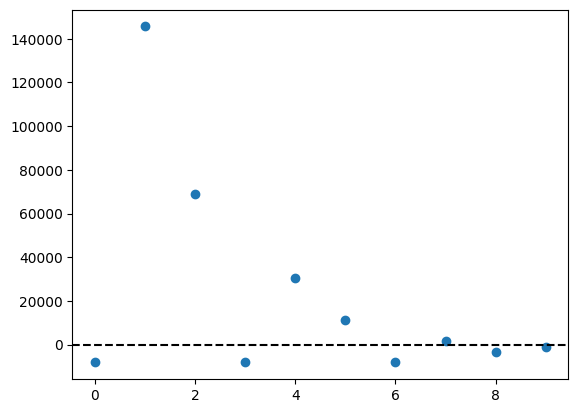

In [ ]:


#delta_r_ML2 = (d*(m_M/(3*m_E))**(1/3))*1.048611175
#############
dt = 1
t_max = T_EM
tolorance = 1000
augment = 1.0486111844
dr = 0.296875
#############

delta_r_L2 = (d*(m_M/(3*m_E))**(1/3)) * augment
all_delta_r_L2 = [delta_r_L2]

v0_L2 = 2*pi*(d_M+delta_r_L2)/T_EM
r_pos , M_pos = orbit_Taylor_optimizer(np.array([d_M+delta_r_L2,0]),np.array([0,v0_L2]),dt,t_max)

change_in_M_rocket_distance = np.linalg.norm(r_pos - M_pos) - delta_r_L2


all_change_in_M_rocket_distance = [change_in_M_rocket_distance]
if change_in_M_rocket_distance > 0 :
    cur_sin = -1
else:
    cur_sin = 1
prev_sin = 0
itNum = 1
while abs(change_in_M_rocket_distance) > tolorance and itNum < 100:
    dr = abs(dr)
    if cur_sin < 0 :
        dr = dr*-1
    if cur_sin * prev_sin < 0 :
        dr = dr/2
    prev_sin = cur_sin
    delta_r_L2 += dr
    all_delta_r_L2 += [delta_r_L2]
    v0_L2 = 2*pi*(d_M+delta_r_L2)/T_EM
    r_pos , M_pos = orbit_Taylor_optimizer(np.array([d_M+delta_r_L2,0]),np.array([0,v0_L2]),dt,t_max)
    change_in_M_rocket_distance = np.linalg.norm(r_pos - M_pos) - delta_r_L2
    all_change_in_M_rocket_distance += [change_in_M_rocket_distance]
    if change_in_M_rocket_distance > 0 :
        cur_sin = -1
    else:
        cur_sin = 1
    itNum += 1

print("delta_r_L2: ",delta_r_L2)
dr = abs(dr)
print("dr:",dr ,"    dr/delta_r:", (dr/delta_r_L2))
print("change in r moon distance final: ",change_in_M_rocket_distance)
print(delta_r_L2/(d*(m_M/(3*m_E))**(1/3)))
print(UDS.sci_e_equal(delta_r_L2/(d*(m_M/(3*m_E))**(1/3)),dr/(d*(m_M/(3*m_E))**(1/3))))


#fig1 = plt.figure(1)
#plt.scatter(np.arange(itNum),all_delta_r_L2)
fig2 = plt.figure(2)
plt.axhline(0, linestyle='--',c='k')
plt.scatter(np.arange(itNum),all_change_in_M_rocket_distance)

plt.show()

##### RK4 Optimization

delta_r_L2:  64520115.789868265
dr: 0.18336868286132812     dr/delta_r: 2.8420389612834966e-09
change in r moon distance final:  3204.775751695037
1.048615606075554
0.000000002980206408


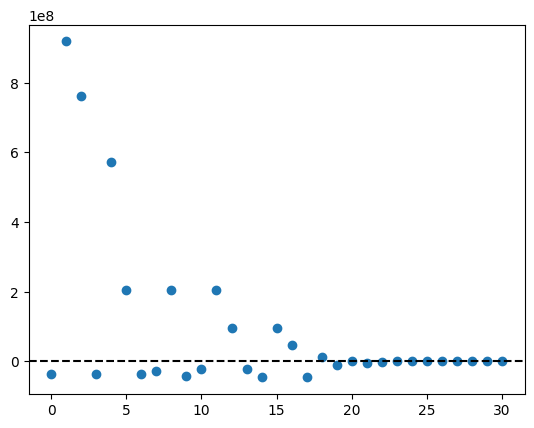

In [65]:
#############
dt = 10
t_max = T_EM
tolorance = 10000
augment = 1.0484375000000001
dr = 96138
#############

delta_r_L2 = (d*(m_M/(3*m_E))**(1/3)) * augment
all_delta_r_L2 = [delta_r_L2]

v0_L2 = 2*pi*(d_M+delta_r_L2)/T_EM
r_pos , M_pos = orbit_RK4_optimizer(np.array([d_M+delta_r_L2,0]),np.array([0,v0_L2]),dt,t_max)

change_in_M_rocket_distance = np.linalg.norm(r_pos - M_pos) - delta_r_L2


all_change_in_M_rocket_distance = [change_in_M_rocket_distance]
if change_in_M_rocket_distance > 0 :
    cur_sin = -1
else:
    cur_sin = 1
prev_sin = 0
itNum = 1
while abs(change_in_M_rocket_distance) > tolorance and itNum < 100:
    dr = abs(dr)
    if cur_sin < 0 :
        dr = dr*-1
    if cur_sin * prev_sin < 0 :
        dr = dr/2
    prev_sin = cur_sin
    delta_r_L2 += dr
    all_delta_r_L2 += [delta_r_L2]
    v0_L2 = 2*pi*(d_M+delta_r_L2)/T_EM
    r_pos , M_pos = orbit_RK4_optimizer(np.array([d_M+delta_r_L2,0]),np.array([0,v0_L2]),dt,t_max)
    change_in_M_rocket_distance = np.linalg.norm(r_pos - M_pos) - delta_r_L2
    all_change_in_M_rocket_distance += [change_in_M_rocket_distance]
    if change_in_M_rocket_distance > 0 :
        cur_sin = -1
    else:
        cur_sin = 1
    itNum += 1

print("delta_r_L2: ",delta_r_L2)
dr = abs(dr)
print("dr:",dr ,"    dr/delta_r:", (dr/delta_r_L2))
print("change in r moon distance final: ",change_in_M_rocket_distance)
print(delta_r_L2/(d*(m_M/(3*m_E))**(1/3)))
print(UDS.sci_e_equal(delta_r_L2/(d*(m_M/(3*m_E))**(1/3)),dr/(d*(m_M/(3*m_E))**(1/3))))


#fig1 = plt.figure(1)
#plt.scatter(np.arange(itNum),all_delta_r_L2)
fig2 = plt.figure(2)
plt.axhline(0, linestyle='--',c='k')
plt.scatter(np.arange(itNum),all_change_in_M_rocket_distance)

plt.show()

#### Final Simulation

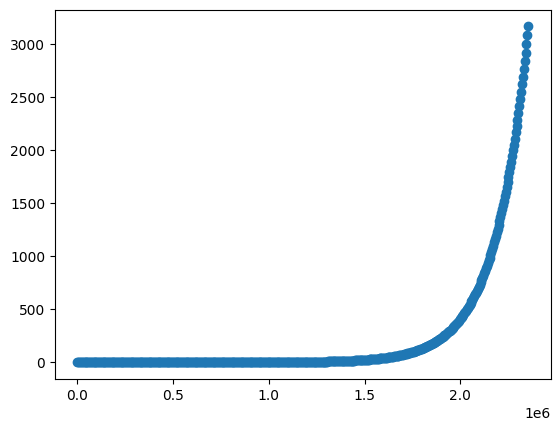

In [66]:
dt = 10
t_max = T_EM
#r_rE = d*0.75
#v_orbit = math.sqrt(G*m_E/r_rE)
delta_r_ML2 = delta_r_L2
v0_L2 = 2*pi*(d_M+delta_r_ML2)/T_EM
r0 = np.array([d_M+delta_r_ML2,0])
v0 = np.array([0,v0_L2])
t = 0
r_pos_shown,E_pos_shown,M_pos_shown,sim_time = orbit_RK4_animation(r0,v0,dt,t_max,15)

fig1 = plt.figure(1)
plt.scatter(sim_time,np.array(moon_rocket_d_list(M_pos_shown,r_pos_shown))-moon_rocket_d_list(M_pos_shown,r_pos_shown)[0])

plt.show()


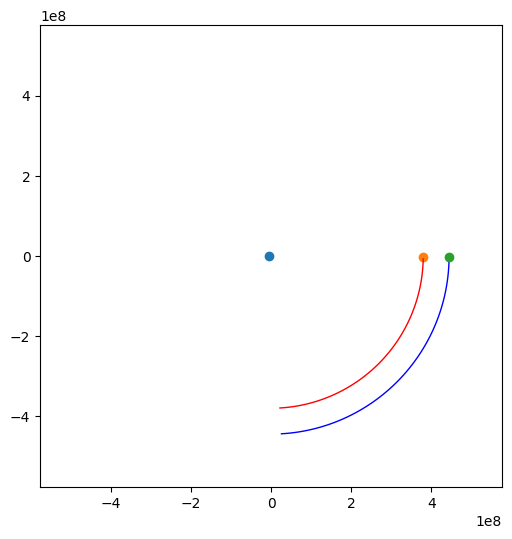

In [67]:
%matplotlib inline
plt.rcParams["animation.html"] = "jshtml"
plt.rcParams['animation.embed_limit'] = 2**128
import matplotlib.animation
###########################################

int_ms=10 # interval between frames in ms
lag=120

##############Picking out frames to show######################


###########################################

fig=plt.figure(figsize=(6,6))
xmin=-1.5*d
xmax=-xmin
ymin=xmin
ymax=xmax
ax=fig.add_subplot(111,autoscale_on=True,xlim=(xmin,xmax),ylim=(ymin,ymax))
ax.set_aspect('equal')
orbit0,=ax.plot([],[],'o-',lw=2)
trail0,=ax.plot([],[],'b-',lw=1)
orbit1,=ax.plot([],[],'o-',lw=2)
trail1,=ax.plot([],[],'r-',lw=1)
orbit2,=ax.plot([],[],'o-',lw=2)
trail2,=ax.plot([],[],'g-',lw=1)
x0,y0,x1,y1,x2,y2=[],[],[],[],[],[]

def animate_all(i):
    modified = []
    if i>lag:
        imin=i-lag
    else:
        imin=0
    
    thisx=[E_pos_shown[i][0]]
    thisy=[E_pos_shown[i][1]]
    orbit0.set_data(thisx,thisy)
    x0=np.array(E_pos_shown)[imin:i,0]
    y0=np.array(E_pos_shown)[imin:i,1]
    trail0.set_data(x0,y0)
    #######
    thisx=[M_pos_shown[i][0]]
    thisy=[M_pos_shown[i][1]]
    orbit1.set_data(thisx,thisy)
    x1=np.array(M_pos_shown)[imin:i,0]
    y1=np.array(M_pos_shown)[imin:i,1]
    trail1.set_data(x1,y1)
    ######
    thisx=[r_pos_shown[i][0]]
    thisy=[r_pos_shown[i][1]]
    orbit2.set_data(thisx,thisy)
    x2=np.array(r_pos_shown)[imin:i,0]
    y2=np.array(r_pos_shown)[imin:i,1]
    trail0.set_data(x2,y2)
    modified+=[orbit0,trail0,orbit1,trail1,orbit2,trail2]
    return modified

ani=matplotlib.animation.FuncAnimation(fig,animate_all,range(1,len(r_pos_shown)),interval=int_ms,blit=True,repeat=False)
ani